In [3]:
import kagglehub

dataset_path = kagglehub.dataset_download("harbhajansingh21/german-traffic-sign-dataset")
print("Dataset path:", dataset_path)

/Users/yigit/CodeProjects/deos-env/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/yigit/CodeProjects/deos-env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 118M/118M [00:12<00:00, 10.1MB/s] 

Extracting files...


Dataset path: /Users/yigit/.cache/kagglehub/datasets/harbhajansingh21/german-traffic-sign-dataset/versions/1


In [4]:
import os

for root, dirs, files in os.walk(dataset_path):
    for file_name in files:
        file_path = os.path.join(root, file_name)
        size_mb = os.path.getsize(file_path) / (1024 * 1024)
        print(f"{file_path}  ({size_mb:.1f} MB)")

/Users/yigit/.cache/kagglehub/datasets/harbhajansingh21/german-traffic-sign-dataset/versions/1/valid.p  (12.9 MB)
/Users/yigit/.cache/kagglehub/datasets/harbhajansingh21/german-traffic-sign-dataset/versions/1/signname.csv  (0.0 MB)
/Users/yigit/.cache/kagglehub/datasets/harbhajansingh21/german-traffic-sign-dataset/versions/1/train.p  (102.2 MB)
/Users/yigit/.cache/kagglehub/datasets/harbhajansingh21/german-traffic-sign-dataset/versions/1/test.p  (37.1 MB)


In [5]:
import pandas as pd

sign_names = pd.read_csv(os.path.join(dataset_path, "signname.csv"))
print("Number of classes:", len(sign_names))
sign_names.head(10)

Number of classes: 43


,ClassId,SignName
0,0,Speed limit (20km/h)
1,1,Speed limit (30km/h)
2,2,Speed limit (50km/h)
3,3,Speed limit (60km/h)
4,4,Speed limit (70km/h)
5,5,Speed limit (80km/h)
6,6,End of speed limit (80km/h)
7,7,Speed limit (100km/h)
8,8,Speed limit (120km/h)
9,9,No passing


In [6]:
import pickle

def load_pickle(file_name):
    file_path = os.path.join(dataset_path, file_name)
    with open(file_path, "rb") as file:
        return pickle.load(file)

train_data = load_pickle("train.p")

print("Type:", type(train_data))
for key, value in train_data.items():
    print(key, "->", type(value), getattr(value, "shape", len(value)))

Type: <class 'dict'>
coords -> <class 'numpy.ndarray'> (34799, 4)
labels -> <class 'numpy.ndarray'> (34799,)
features -> <class 'numpy.ndarray'> (34799, 32, 32, 3)
sizes -> <class 'numpy.ndarray'> (34799, 2)


In [7]:
valid_data = load_pickle("valid.p")
test_data = load_pickle("test.p")

X_train, y_train = train_data["features"], train_data["labels"]
X_valid, y_valid = valid_data["features"], valid_data["labels"]
X_test, y_test = test_data["features"], test_data["labels"]

print("Train:", X_train.shape, y_train.shape)
print("Valid:", X_valid.shape, y_valid.shape)
print("Test: ", X_test.shape, y_test.shape)

print("Pixel value range:", X_train.min(), "-", X_train.max())
print("First 10 labels:", y_train[:10])

Train: (34799, 32, 32, 3) (34799,)
Valid: (4410, 32, 32, 3) (4410,)
Test:  (12630, 32, 32, 3) (12630,)
Pixel value range: 0 - 255
First 10 labels: [41 41 41 41 41 41 41 41 41 41]


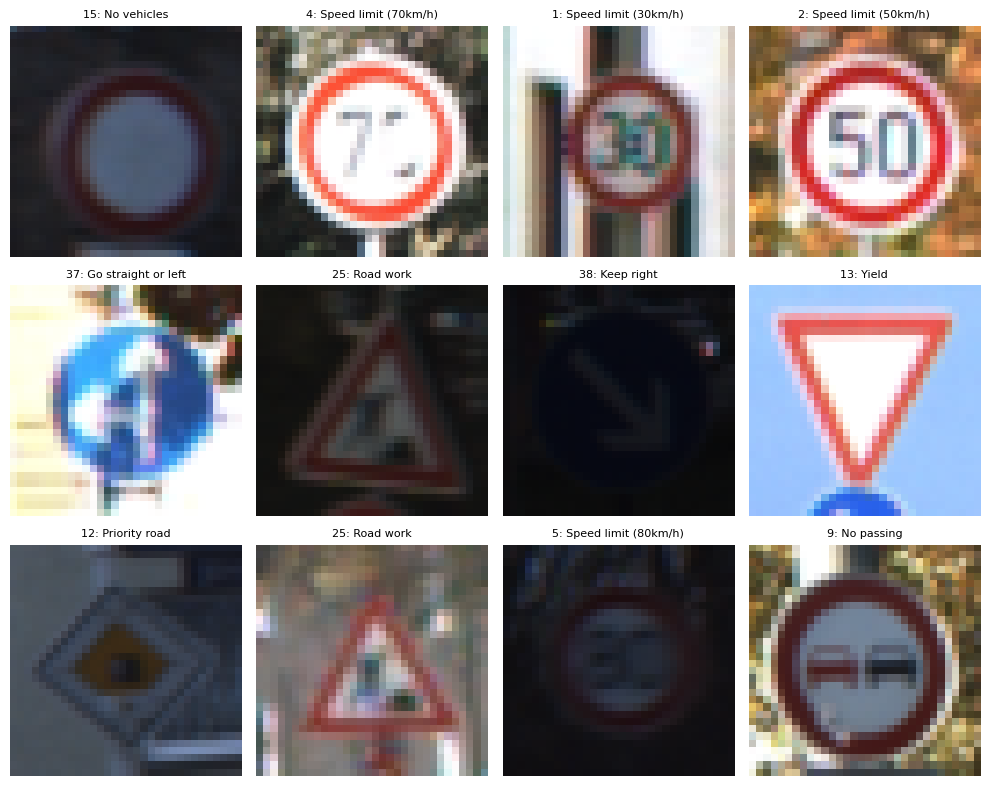

In [8]:
import matplotlib.pyplot as plt
import numpy as np

random_indices = np.random.choice(len(X_train), 12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for ax, index in zip(axes.flat, random_indices):
    label = y_train[index]
    ax.imshow(X_train[index])
    ax.set_title(f"{label}: {sign_names.loc[label, 'SignName']}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

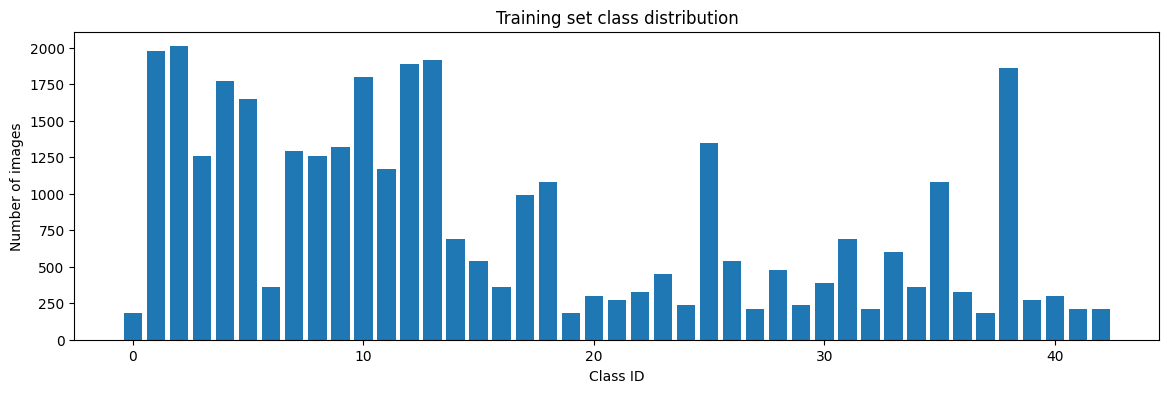

Most images: class 2 -> 2010
Fewest images: class 0 -> 180


In [9]:
class_counts = np.bincount(y_train, minlength=43)

plt.figure(figsize=(14, 4))
plt.bar(range(43), class_counts)
plt.xlabel("Class ID")
plt.ylabel("Number of images")
plt.title("Training set class distribution")
plt.show()

print("Most images: class", class_counts.argmax(), "->", class_counts.max())
print("Fewest images: class", class_counts.argmin(), "->", class_counts.min())

In [10]:
X_train_norm = X_train.astype("float32") / 255.0
X_valid_norm = X_valid.astype("float32") / 255.0
X_test_norm = X_test.astype("float32") / 255.0

print("Before:", X_train.dtype, X_train[0, 0, 0])
print("After: ", X_train_norm.dtype, X_train_norm[0, 0, 0])
print("New range:", X_train_norm.min(), "-", X_train_norm.max())

Before: uint8 [28 25 24]
After:  float32 [0.10980392 0.09803922 0.09411765]
New range: 0.0 - 1.0


In [11]:
import torch

X_train_tensor = torch.from_numpy(X_train_norm).permute(0, 3, 1, 2)
X_valid_tensor = torch.from_numpy(X_valid_norm).permute(0, 3, 1, 2)
X_test_tensor = torch.from_numpy(X_test_norm).permute(0, 3, 1, 2)

y_train_tensor = torch.from_numpy(y_train).long()
y_valid_tensor = torch.from_numpy(y_valid).long()
y_test_tensor = torch.from_numpy(y_test).long()

print("Images:", X_train_tensor.shape, X_train_tensor.dtype)
print("Labels:", y_train_tensor.shape, y_train_tensor.dtype)

Images: torch.Size([34799, 3, 32, 32]) torch.float32
Labels: torch.Size([34799]) torch.int64


In [12]:
from torch.utils.data import TensorDataset, DataLoader

batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
valid_dataset = TensorDataset(X_valid_tensor, y_valid_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("Number of train batches:", len(train_loader))

images, labels = next(iter(train_loader))
print("One batch of images:", images.shape)
print("One batch of labels:", labels.shape)
print("Labels in this batch:", labels[:20])

Number of train batches: 544
One batch of images: torch.Size([64, 3, 32, 32])
One batch of labels: torch.Size([64])
Labels in this batch: tensor([ 9, 31, 20, 31, 38, 25, 25,  2, 17, 33, 32,  0,  2, 34, 10,  2, 33, 19,
         1, 38])


In [13]:
import torch.nn as nn

class TrafficSignCNN(nn.Module):
    def __init__(self, num_classes=43):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = TrafficSignCNN()
print(model)

output = model(images)
print("Output shape:", output.shape)
print("Scores for the first image:", output[0])

TrafficSignCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=43, bias=True)
  )
)
Output shape: torch.Size([64, 43])
Scores for the first image: tensor([ 0.0838,  0.0157, -0.0603,  0.0379,  0.0365,  0.0414,  0.0477, -0.0186,
        -0.0079,  0.0283,  0.0733, -0.0291,  0.0330,  0.0351,  0.0517, -0.0648,
        -0.0020, -0.0048,  0.0741,  0.0510,  0.0261,  0.0427,  0.0553, -0.0510,
        -0.0524,  0.0125,  0.0912,  0.0025, -0.0706, -0.0492, -0.0326, -0.0712,
      

In [25]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Device:", device)

model = TrafficSignCNN().to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)

outputs = model(images)
loss = loss_function(outputs, labels)
print("Loss before training:", loss.item())

Device: mps
Loss before training: 3.748727321624756


In [26]:
def train_one_epoch(model, data_loader, loss_function, optimizer, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in data_loader:
        images, labels = images.to(device), labels.to(device)

        # 1. Tahmin et
        outputs = model(images)

        # 2. Hatayı ölç
        loss = loss_function(outputs, labels)

        # 3. Ayarları düzelt
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # İstatistikleri topla
        total_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total
    return average_loss, accuracy


train_loss, train_accuracy = train_one_epoch(model, train_loader, loss_function, optimizer, device)
print(f"Train loss: {train_loss:.4f} | Train accuracy: {train_accuracy:.2%}")

Train loss: 1.3393 | Train accuracy: 62.22%


In [27]:
def evaluate(model, data_loader, loss_function, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = loss_function(outputs, labels)

            total_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total
    return average_loss, accuracy


valid_loss, valid_accuracy = evaluate(model, valid_loader, loss_function, device)
print(f"Valid loss: {valid_loss:.4f} | Valid accuracy: {valid_accuracy:.2%}")

Valid loss: 0.7972 | Valid accuracy: 77.37%


In [28]:
num_epochs = 10

model = TrafficSignCNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

history = {
    "train_loss": [],
    "train_accuracy": [],
    "valid_loss": [],
    "valid_accuracy": [],
}

for epoch in range(1, num_epochs + 1):
    train_loss, train_accuracy = train_one_epoch(model, train_loader, loss_function, optimizer, device)
    valid_loss, valid_accuracy = evaluate(model, valid_loader, loss_function, device)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["valid_loss"].append(valid_loss)
    history["valid_accuracy"].append(valid_accuracy)

    print(
        f"Epoch {epoch:2d} | "
        f"Train loss: {train_loss:.4f}, acc: {train_accuracy:.2%} | "
        f"Valid loss: {valid_loss:.4f}, acc: {valid_accuracy:.2%}"
    )

Epoch  1 | Train loss: 1.3296, acc: 62.50% | Valid loss: 0.7844, acc: 79.46%
Epoch  2 | Train loss: 0.2050, acc: 94.37% | Valid loss: 0.6416, acc: 85.49%
Epoch  3 | Train loss: 0.1026, acc: 97.27% | Valid loss: 0.5762, acc: 86.05%
Epoch  4 | Train loss: 0.0626, acc: 98.41% | Valid loss: 0.5715, acc: 88.39%
Epoch  5 | Train loss: 0.0473, acc: 98.73% | Valid loss: 0.6547, acc: 87.57%
Epoch  6 | Train loss: 0.0338, acc: 99.11% | Valid loss: 0.5554, acc: 89.27%
Epoch  7 | Train loss: 0.0260, acc: 99.33% | Valid loss: 0.5054, acc: 90.02%
Epoch  8 | Train loss: 0.0276, acc: 99.21% | Valid loss: 0.5384, acc: 89.30%
Epoch  9 | Train loss: 0.0180, acc: 99.51% | Valid loss: 0.4331, acc: 91.45%
Epoch 10 | Train loss: 0.0155, acc: 99.52% | Valid loss: 0.4477, acc: 90.66%


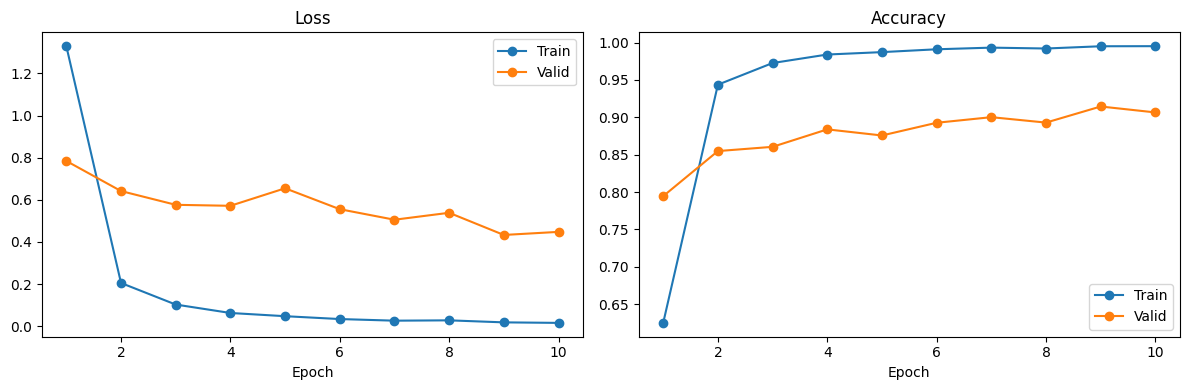

In [29]:
epochs = range(1, num_epochs + 1)

fig, (ax_loss, ax_accuracy) = plt.subplots(1, 2, figsize=(12, 4))

ax_loss.plot(epochs, history["train_loss"], marker="o", label="Train")
ax_loss.plot(epochs, history["valid_loss"], marker="o", label="Valid")
ax_loss.set_title("Loss")
ax_loss.set_xlabel("Epoch")
ax_loss.legend()

ax_accuracy.plot(epochs, history["train_accuracy"], marker="o", label="Train")
ax_accuracy.plot(epochs, history["valid_accuracy"], marker="o", label="Valid")
ax_accuracy.set_title("Accuracy")
ax_accuracy.set_xlabel("Epoch")
ax_accuracy.legend()

plt.tight_layout()
plt.show()

In [30]:
model_path = "traffic_sign_cnn.pt"
torch.save(model.state_dict(), model_path)
print("Saved:", model_path, f"({os.path.getsize(model_path) / (1024 * 1024):.2f} MB)")

loaded_model = TrafficSignCNN().to(device)
loaded_model.load_state_dict(torch.load(model_path, map_location=device))

original_loss, original_accuracy = evaluate(model, valid_loader, loss_function, device)
loaded_loss, loaded_accuracy = evaluate(loaded_model, valid_loader, loss_function, device)

print(f"Original model: {original_accuracy:.2%}")
print(f"Loaded model:   {loaded_accuracy:.2%}")

Saved: traffic_sign_cnn.pt (2.10 MB)
Original model: 90.66%
Loaded model:   90.66%


In [31]:
test_loss, test_accuracy = evaluate(model, test_loader, loss_function, device)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_accuracy:.2%}")

Test loss: 0.5943 | Test accuracy: 90.40%


In [32]:
def get_predictions(model, data_loader, device):
    model.eval()
    all_predictions = []
    with torch.no_grad():
        for images, _ in data_loader:
            outputs = model(images.to(device))
            all_predictions.append(outputs.argmax(dim=1).cpu())
    return torch.cat(all_predictions).numpy()


test_predictions = get_predictions(model, test_loader, device)
print("Wrong predictions:", (test_predictions != y_test).sum(), "/", len(y_test))

per_class_accuracy = np.array([
    (test_predictions[y_test == class_id] == class_id).mean()
    for class_id in range(43)
])

worst_classes = np.argsort(per_class_accuracy)[:5]

print("\nWorst 5 classes:")
for class_id in worst_classes:
    name = sign_names.loc[class_id, "SignName"]
    print(
        f"{class_id:2d} | {name:<45} | "
        f"test acc: {per_class_accuracy[class_id]:.2%} | "
        f"train images: {class_counts[class_id]}"
    )

Wrong predictions: 1213 / 12630

Worst 5 classes:
30 | Beware of ice/snow                            | test acc: 49.33% | train images: 390
27 | Pedestrians                                   | test acc: 50.00% | train images: 210
21 | Double curve                                  | test acc: 56.67% | train images: 270
29 | Bicycles crossing                             | test acc: 67.78% | train images: 240
 0 | Speed limit (20km/h)                          | test acc: 70.00% | train images: 180


In [33]:
from collections import Counter

for class_id in worst_classes:
    name = sign_names.loc[class_id, "SignName"]
    wrong_mask = (y_test == class_id) & (test_predictions != class_id)
    wrong_predictions = test_predictions[wrong_mask]

    print(f"\n{class_id} | {name} -> most often predicted as:")
    for predicted_id, count in Counter(wrong_predictions).most_common(3):
        predicted_name = sign_names.loc[predicted_id, "SignName"]
        print(f"    {predicted_id:2d} | {predicted_name:<40} ({count} times)")


30 | Beware of ice/snow -> most often predicted as:
    24 | Road narrows on the right                (30 times)
    20 | Dangerous curve to the right             (23 times)
    23 | Slippery road                            (7 times)

27 | Pedestrians -> most often predicted as:
    26 | Traffic signals                          (20 times)
    11 | Right-of-way at the next intersection    (4 times)
    31 | Wild animals crossing                    (3 times)

21 | Double curve -> most often predicted as:
    23 | Slippery road                            (27 times)
    31 | Wild animals crossing                    (7 times)
    25 | Road work                                (2 times)

29 | Bicycles crossing -> most often predicted as:
    24 | Road narrows on the right                (16 times)
    25 | Road work                                (12 times)
    28 | Children crossing                        (1 times)

0 | Speed limit (20km/h) -> most often predicted as:
     1 | Speed limit (

In [34]:
class TrafficSignCNNv2(nn.Module):
    def __init__(self, num_classes=43):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1: 32x32 -> 16x16
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2: 16x16 -> 8x8
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3: 8x8 -> 4x4
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model_v2 = TrafficSignCNNv2().to(device)

images, labels = next(iter(train_loader))
output = model_v2(images.to(device))
print("Output shape:", output.shape)

parameter_count = sum(p.numel() for p in model_v2.parameters())
print("Number of parameters:", parameter_count)

Output shape: torch.Size([64, 43])
Number of parameters: 675659


In [35]:
import time

print("Device:", device)

num_epochs = 15
best_model_path = "traffic_sign_cnn_v2_best.pt"

model_v2 = TrafficSignCNNv2().to(device)
optimizer = torch.optim.Adam(model_v2.parameters(), lr=0.001)

history_v2 = {
    "train_loss": [],
    "train_accuracy": [],
    "valid_loss": [],
    "valid_accuracy": [],
}
best_valid_accuracy = 0.0

for epoch in range(1, num_epochs + 1):
    start_time = time.time()

    train_loss, train_accuracy = train_one_epoch(model_v2, train_loader, loss_function, optimizer, device)
    valid_loss, valid_accuracy = evaluate(model_v2, valid_loader, loss_function, device)

    history_v2["train_loss"].append(train_loss)
    history_v2["train_accuracy"].append(train_accuracy)
    history_v2["valid_loss"].append(valid_loss)
    history_v2["valid_accuracy"].append(valid_accuracy)

    saved_note = ""
    if valid_accuracy > best_valid_accuracy:
        best_valid_accuracy = valid_accuracy
        torch.save(model_v2.state_dict(), best_model_path)
        saved_note = "  <- best, saved"

    epoch_time = time.time() - start_time
    print(
        f"Epoch {epoch:2d} | "
        f"Train loss: {train_loss:.4f}, acc: {train_accuracy:.2%} | "
        f"Valid loss: {valid_loss:.4f}, acc: {valid_accuracy:.2%} | "
        f"{epoch_time:.0f}s{saved_note}"
    )

print(f"\nBest valid accuracy: {best_valid_accuracy:.2%}")

Device: mps
Epoch  1 | Train loss: 1.1010, acc: 67.52% | Valid loss: 0.1645, acc: 95.78% | 11s  <- best, saved
Epoch  2 | Train loss: 0.1446, acc: 95.59% | Valid loss: 0.0997, acc: 97.32% | 11s  <- best, saved
Epoch  3 | Train loss: 0.0838, acc: 97.44% | Valid loss: 0.0733, acc: 97.98% | 11s  <- best, saved
Epoch  4 | Train loss: 0.0617, acc: 98.08% | Valid loss: 0.1015, acc: 96.76% | 10s
Epoch  5 | Train loss: 0.0596, acc: 98.18% | Valid loss: 0.0565, acc: 98.28% | 11s  <- best, saved
Epoch  6 | Train loss: 0.0434, acc: 98.66% | Valid loss: 0.1078, acc: 98.48% | 11s  <- best, saved
Epoch  7 | Train loss: 0.0366, acc: 98.88% | Valid loss: 0.0970, acc: 97.64% | 11s
Epoch  8 | Train loss: 0.0351, acc: 98.94% | Valid loss: 0.0760, acc: 98.30% | 11s
Epoch  9 | Train loss: 0.0349, acc: 98.91% | Valid loss: 0.0441, acc: 98.98% | 10s  <- best, saved
Epoch 10 | Train loss: 0.0348, acc: 98.88% | Valid loss: 0.0822, acc: 98.14% | 11s
Epoch 11 | Train loss: 0.0238, acc: 99.26% | Valid loss: 0.048

In [36]:
best_model = TrafficSignCNNv2().to(device)
best_model.load_state_dict(torch.load(best_model_path, map_location=device))

test_loss, test_accuracy = evaluate(best_model, test_loader, loss_function, device)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_accuracy:.2%}")

test_predictions_v2 = get_predictions(best_model, test_loader, device)
print("Wrong predictions:", (test_predictions_v2 != y_test).sum(), "/", len(y_test))

per_class_accuracy_v2 = np.array([
    (test_predictions_v2[y_test == class_id] == class_id).mean()
    for class_id in range(43)
])

print("\nWorst 5 classes (v2):")
for class_id in np.argsort(per_class_accuracy_v2)[:5]:
    name = sign_names.loc[class_id, "SignName"]
    print(
        f"{class_id:2d} | {name:<45} | "
        f"v1: {per_class_accuracy[class_id]:.2%} -> v2: {per_class_accuracy_v2[class_id]:.2%}"
    )

Test loss: 0.0794 | Test accuracy: 98.12%
Wrong predictions: 237 / 12630

Worst 5 classes (v2):
 6 | End of speed limit (80km/h)                   | v1: 82.00% -> v2: 71.33%
21 | Double curve                                  | v1: 56.67% -> v2: 72.22%
30 | Beware of ice/snow                            | v1: 49.33% -> v2: 77.33%
24 | Road narrows on the right                     | v1: 83.33% -> v2: 81.11%
41 | End of no passing                             | v1: 86.67% -> v2: 81.67%


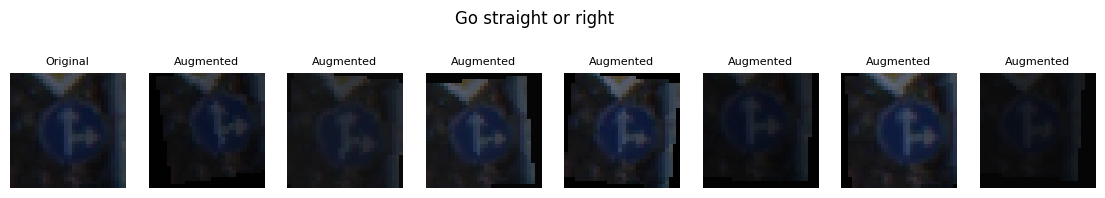

In [37]:
from torchvision.transforms import v2

train_transform = v2.Compose([
    v2.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    v2.ColorJitter(brightness=0.4, contrast=0.4),
])

sample_index = 1000
sample_image = X_train_tensor[sample_index]
sample_label = y_train[sample_index]

fig, axes = plt.subplots(1, 8, figsize=(14, 2.5))
axes[0].imshow(sample_image.permute(1, 2, 0).numpy())
axes[0].set_title("Original", fontsize=8)
axes[0].axis("off")

for ax in axes[1:]:
    augmented = train_transform(sample_image)
    ax.imshow(augmented.permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title("Augmented", fontsize=8)
    ax.axis("off")

plt.suptitle(sign_names.loc[sample_label, "SignName"])
plt.show()

In [38]:
from torch.utils.data import Dataset


class AugmentedDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = self.transform(self.images[index])
        return image, self.labels[index]


augmented_train_dataset = AugmentedDataset(X_train_tensor, y_train_tensor, train_transform)
augmented_train_loader = DataLoader(augmented_train_dataset, batch_size=batch_size, shuffle=True)


def train_model(model, train_loader, num_epochs, save_path):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    history = {"train_loss": [], "train_accuracy": [], "valid_loss": [], "valid_accuracy": []}
    best_valid_accuracy = 0.0

    for epoch in range(1, num_epochs + 1):
        start_time = time.time()

        train_loss, train_accuracy = train_one_epoch(model, train_loader, loss_function, optimizer, device)
        valid_loss, valid_accuracy = evaluate(model, valid_loader, loss_function, device)

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["valid_loss"].append(valid_loss)
        history["valid_accuracy"].append(valid_accuracy)

        saved_note = ""
        if valid_accuracy > best_valid_accuracy:
            best_valid_accuracy = valid_accuracy
            torch.save(model.state_dict(), save_path)
            saved_note = "  <- best, saved"

        print(
            f"Epoch {epoch:2d} | "
            f"Train loss: {train_loss:.4f}, acc: {train_accuracy:.2%} | "
            f"Valid loss: {valid_loss:.4f}, acc: {valid_accuracy:.2%} | "
            f"{time.time() - start_time:.0f}s{saved_note}"
        )

    print(f"\nBest valid accuracy: {best_valid_accuracy:.2%}")
    return history


print("Device:", device)
model_v3 = TrafficSignCNNv2().to(device)
history_v3 = train_model(model_v3, augmented_train_loader, num_epochs=20, save_path="traffic_sign_cnn_v3_aug_best.pt")

Device: mps
Epoch  1 | Train loss: 2.0051, acc: 39.67% | Valid loss: 0.7120, acc: 78.59% | 15s  <- best, saved
Epoch  2 | Train loss: 0.6632, acc: 78.05% | Valid loss: 0.2659, acc: 93.13% | 15s  <- best, saved
Epoch  3 | Train loss: 0.3520, acc: 88.62% | Valid loss: 0.1808, acc: 95.56% | 15s  <- best, saved
Epoch  4 | Train loss: 0.2516, acc: 92.02% | Valid loss: 0.1363, acc: 95.99% | 15s  <- best, saved
Epoch  5 | Train loss: 0.1981, acc: 93.44% | Valid loss: 0.1153, acc: 97.32% | 15s  <- best, saved
Epoch  6 | Train loss: 0.1646, acc: 94.64% | Valid loss: 0.0780, acc: 97.73% | 15s  <- best, saved
Epoch  7 | Train loss: 0.1454, acc: 95.51% | Valid loss: 0.0862, acc: 98.00% | 15s  <- best, saved
Epoch  8 | Train loss: 0.1283, acc: 96.01% | Valid loss: 0.0749, acc: 98.25% | 15s  <- best, saved
Epoch  9 | Train loss: 0.1149, acc: 96.27% | Valid loss: 0.0623, acc: 97.87% | 15s
Epoch 10 | Train loss: 0.1107, acc: 96.51% | Valid loss: 0.0844, acc: 97.89% | 15s
Epoch 11 | Train loss: 0.0899,

In [39]:
model_v3_best = TrafficSignCNNv2().to(device)
model_v3_best.load_state_dict(torch.load("traffic_sign_cnn_v3_aug_best.pt", map_location=device))

torch.manual_seed(0)
X_test_hard = torch.stack([train_transform(image) for image in X_test_tensor])
hard_test_loader = DataLoader(TensorDataset(X_test_hard, y_test_tensor), batch_size=batch_size)

print(f"{'Model':<6} | {'Normal test':>12} | {'Hard test':>10}")
for model_name, trained_model in [("v2", best_model), ("v3", model_v3_best)]:
    _, normal_accuracy = evaluate(trained_model, test_loader, loss_function, device)
    _, hard_accuracy = evaluate(trained_model, hard_test_loader, loss_function, device)
    print(f"{model_name:<6} | {normal_accuracy:>12.2%} | {hard_accuracy:>10.2%}")

Model  |  Normal test |  Hard test
v2     |       98.12% |     86.71%
v3     |       98.79% |     97.53%
